# Frozen RoBERTa baseline for ternary AI-text detection

1. Extract a English `academic` + `wiki` slice from the DetectRL-X ternary JSON. Keep the dataset's supplied `train` and `test` partitions.
2. Split the supplied training partition into train/validation groups by `pair_id`.
3. Extract frozen `roberta-base` mean-pooled embeddings.
4. Train Logistic Regression on those embeddings.
5. Report macro-F1, per-class precision/recall, confusion matrix, and qualitative examples.

**Dataset:** `trinary_general_256_open` in DetectRL-X , which is 256-token truncated.  
**Data Sampling:** up to 1,000 source pairs per domain in train and 250 per domain in test. The extraction script balances sampling across LLMs within each domain.

> Note: this is not fine-tuning RoBERTa. The transformer weights remain frozen; only the Logistic Regression classifier is fitted.


## 0. Runtime setup

In Colab, select **Runtime → Change runtime type → T4 GPU** if available.

## 1. Download the dataset and extraction script


In [ ]:
from huggingface_hub import hf_hub_download
from pathlib import Path
import os

REPO_ID = "WUJUNCHAO/DetectRL-X"
DATA_FILE = "Ternary/trinary_general_256_open.json"

json_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=DATA_FILE,
    repo_type="dataset",
)
print("Dataset:", json_path)

# Upload extract_ternary_subset.py to the Colab session, or place it in the current directory.
from google.colab import files
uploaded = files.upload()  # choose extract_ternary_subset.py


Ternary/trinary_general_256_open.json: reconstructing file:   0%|          |  0.00B / 1.10GB            

Ternary/trinary_general_256_open.json: downloading bytes:           |  0.00B            

Dataset: /root/.cache/huggingface/hub/datasets--WUJUNCHAO--DetectRL-X/snapshots/ccc9a0a74793dd3448e0da1650b430f5df1b0402/Ternary/trinary_general_256_open.json


Saving extract_ternary_subset.py to extract_ternary_subset.py


## 2. Extract a balanced slice

The script samples round-robin across model groups to create a balanced slice with 1,200 observations in each domain.

In [ ]:
!python -m pip install --user ijson

OUTPUT_CSV = "ternary_academic_wiki_256.csv"

!python extract_ternary_subset.py "$json_path" --lang english --domains academic,wiki --train-per-domain 1000 --test-per-domain 250 --seed 42 --out "$OUTPUT_CSV"

import pandas as pd
df = pd.read_csv(OUTPUT_CSV)
print(df.shape)
display(df.groupby(["split", "domain", "label"]).size().unstack(fill_value=0))
display(df.groupby(["split", "domain", "model"]).size().unstack(fill_value=0))


Wrote 7,500 text rows from 2,500 source pairs to ternary_academic_wiki_256.csv
Selected source pairs by split/domain:
  test/academic: 250
  test/wiki: 250
  train/academic: 1,000
  train/wiki: 1,000
Text rows by label: {'human': 2500, 'ai_generated': 2500, 'ai_refined': 2500}
Text rows by split: {'train': 6000, 'test': 1500}
Text rows by domain: {'wiki': 3750, 'academic': 3750}
(7500, 7)


label           ai_generated  ai_refined  human
split domain                                   
test  Academic           250         250    250
      Wiki               250         250    250
train Academic          1000        1000   1000
      Wiki              1000        1000   1000

model           deepseek-v3  gemini-2.5-flash  gpt-4o  qwen-max
split domain                                                   
test  Academic          189               189     186       186
      Wiki              189               189     186       186
train Academic          750               750     750       750
      Wiki              750               750     750       750

## 3. Validation Split

The source `test` split remains untouched. Validation is created only from source `train`, with all rows sharing a `pair_id` assigned to the same side.

If a source observation is missing one of its three text fields, it contributes only the available labels. Check the class distribution before proceeding.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter

required = {"text", "label", "pair_id", "lang", "model", "domain", "split"}
missing = required - set(df.columns)
assert not missing, f"Missing columns: {missing}"

df = df.dropna(subset=["text", "label", "pair_id"]).copy()
df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(str)
df["pair_id"] = df["pair_id"].astype(str)
df["split"] = df["split"].astype(str).str.lower()

print("Overall label counts:")
display(df["label"].value_counts())
print("Supplied split × label:")
display(pd.crosstab(df["split"], df["label"]))

train_all = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

assert len(train_all) > 0 and len(test_df) > 0, "Need non-empty train and test partitions."

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
fit_idx, val_idx = next(gss.split(train_all, groups=train_all["pair_id"]))

fit_df = train_all.iloc[fit_idx].reset_index(drop=True)
val_df = train_all.iloc[val_idx].reset_index(drop=True)

fit_pairs = set(fit_df["pair_id"])
val_pairs = set(val_df["pair_id"])
test_pairs = set(test_df["pair_id"])
assert fit_pairs.isdisjoint(val_pairs)
assert fit_pairs.isdisjoint(test_pairs)
assert val_pairs.isdisjoint(test_pairs)

for name, part in [("fit", fit_df), ("validation", val_df), ("test", test_df)]:
    print(f"\\n{name}: {len(part):,} texts, {part['pair_id'].nunique():,} pairs")
    display(part["label"].value_counts())


Overall label counts:


,count
label,
human,2500
ai_generated,2500
ai_refined,2500


Supplied split × label:


label,ai_generated,ai_refined,human
split,,,
test,500,500,500
train,2000,2000,2000


\nfit: 5,100 texts, 1,700 pairs


,count
label,
human,1700
ai_generated,1700
ai_refined,1700


\nvalidation: 900 texts, 300 pairs


,count
label,
human,300
ai_generated,300
ai_refined,300


\ntest: 1,500 texts, 500 pairs


,count
label,
human,500
ai_generated,500
ai_refined,500


## 4. Load frozen RoBERTa and extract embeddings

We use attention-mask-aware mean pooling over the final hidden states. This produces one fixed-size vector per text. RoBERTa is in evaluation mode and gradients are disabled.

The source dataset is already truncated to 256 tokens, and the tokenizer is also configured with `max_length=256` as a safety limit.

In [ ]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

MODEL_NAME = "roberta-base"
MAX_LENGTH = 256
BATCH_SIZE = 16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device)
encoder.eval()
for param in encoder.parameters():
    param.requires_grad = False

class TextDataset(Dataset):
    def __init__(self, texts):
        self.texts = list(texts)
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        return self.texts[idx]

@torch.inference_mode()
def embed_texts(texts, batch_size=BATCH_SIZE):
    loader = DataLoader(TextDataset(texts), batch_size=batch_size, shuffle=False)
    all_embeddings = []
    for batch_texts in tqdm(loader, leave=False):
        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt",
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}
        outputs = encoder(**encoded)
        hidden = outputs.last_hidden_state
        mask = encoded["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embeddings.append(pooled.cpu().numpy().astype("float32"))
    return np.concatenate(all_embeddings, axis=0)

X_fit = embed_texts(fit_df["text"])
X_val = embed_texts(val_df["text"])
X_test = embed_texts(test_df["text"])

y_fit = fit_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Embedding shapes:", X_fit.shape, X_val.shape, X_test.shape)


Device: cuda


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (4 outputs left out)

  0%|          | 0/319 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

Embedding shapes: (5100, 768) (900, 768) (1500, 768)


## 5. Logical Regression classifier and evaluate on validation

Validation accuracy: 0.9333
Validation macro-F1: 0.9333
              precision    recall  f1-score   support

ai_generated     0.9700    0.9700    0.9700       300
  ai_refined     0.9003    0.9033    0.9018       300
       human     0.9298    0.9267    0.9282       300

    accuracy                         0.9333       900
   macro avg     0.9334    0.9333    0.9333       900
weighted avg     0.9334    0.9333    0.9333       900



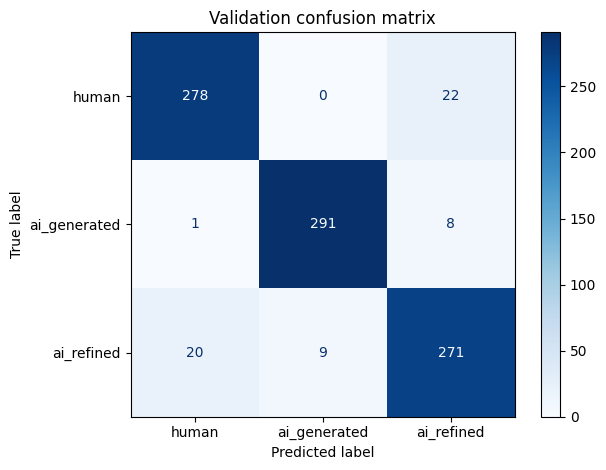

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score
)
import matplotlib.pyplot as plt

classifier = LogisticRegression(
    max_iter=2000,
    C=1.0,
    class_weight="balanced",
    random_state=42,
)
classifier.fit(X_fit, y_fit)

val_pred = classifier.predict(X_val)
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Validation macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 4))
print(classification_report(y_val, val_pred, digits=4, zero_division=0))

labels = ["human", "ai_generated", "ai_refined"]
ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred, labels=labels, display_labels=labels,
    cmap="Blues", values_format="d"
)
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()


## 6. Final evaluation on the held-out supplied test split

After checking the validation results, fit the classifier on all supplied training data (fit + validation) and evaluate once on the supplied test split.

Test accuracy: 0.882
Test macro-F1: 0.8837
              precision    recall  f1-score   support

ai_generated     0.9880    0.8260    0.8998       500
  ai_refined     0.7795    0.9120    0.8406       500
       human     0.9135    0.9080    0.9107       500

    accuracy                         0.8820      1500
   macro avg     0.8937    0.8820    0.8837      1500
weighted avg     0.8937    0.8820    0.8837      1500



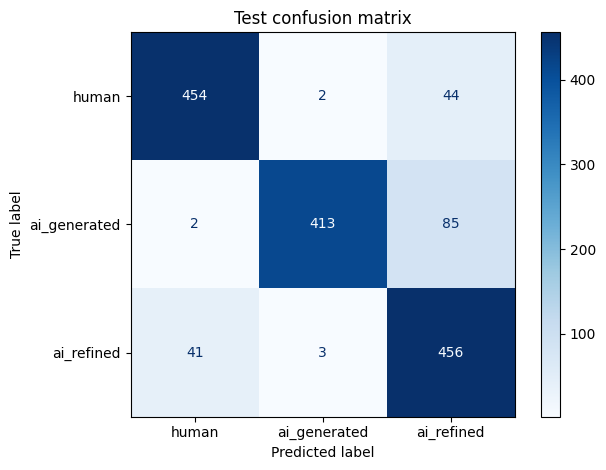

In [ ]:
X_train_full = np.concatenate([X_fit, X_val], axis=0)
y_train_full = np.concatenate([y_fit, y_val], axis=0)

final_classifier = LogisticRegression(
    max_iter=2000,
    C=1.0,
    class_weight="balanced",
    random_state=42,
)
final_classifier.fit(X_train_full, y_train_full)

test_pred = final_classifier.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Test macro-F1:", round(f1_score(y_test, test_pred, average="macro"), 4))
print(classification_report(y_test, test_pred, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=labels, display_labels=labels,
    cmap="Blues", values_format="d"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()


## 7. Qualitative error analysis

In [ ]:
results = test_df.copy()
results["prediction"] = test_pred
results["correct"] = results["label"] == results["prediction"]

print("Correct examples:")
display(results[results["correct"]][
    ["label", "prediction", "domain", "model", "pair_id", "text"]
].head(5))

print("Incorrect examples:")
display(results[~results["correct"]][
    ["label", "prediction", "domain", "model", "pair_id", "text"]
].head(10))

print("Error counts by true label and predicted label:")
display(pd.crosstab(results["label"], results["prediction"]))

print("Accuracy by domain:")
display(results.groupby("domain")["correct"].agg(["count", "mean"]))
print("Accuracy by model:")
display(results.groupby("model")["correct"].agg(["count", "mean"]).sort_values("mean"))


Correct examples:


,label,prediction,domain,model,pair_id,text
0,human,human,Wiki,deepseek-v3,36800,Adam's Testament is a Canadian 2017 drama film...
1,ai_generated,ai_generated,Wiki,deepseek-v3,36800,Adam's Testament Overview Adam's Testament is ...
2,ai_refined,ai_refined,Wiki,deepseek-v3,36800,*Adam's Testament* is a 2017 Canadian drama fi...
3,human,human,Wiki,deepseek-v3,36806,Web in Front is a song by American indie rock ...
5,ai_refined,ai_refined,Wiki,deepseek-v3,36806,"""Web in Front"" is a track by the American indi..."


Incorrect examples:


,label,prediction,domain,model,pair_id,text
4,ai_generated,ai_refined,Wiki,deepseek-v3,36806,"""Web in Front"" ""Web in Front"" is an influentia..."
7,ai_generated,ai_refined,Wiki,deepseek-v3,36811,Colorado in the American Civil War During the ...
13,ai_generated,ai_refined,Wiki,deepseek-v3,36813,Ellen Ratner Early Life and Education Ellen Ra...
22,ai_generated,ai_refined,Wiki,deepseek-v3,36821,2016 Tooting by-election The Tooting by-electi...
40,ai_generated,ai_refined,Wiki,deepseek-v3,36839,Smash Hits. . . Unplugged! Smash Hits. . . Unp...
45,human,ai_refined,Wiki,deepseek-v3,36847,Bobby Sheng (; born April 1972) is a Taiwanese...
52,ai_generated,ai_refined,Wiki,deepseek-v3,36852,Delahaye 145 The Delahaye 145 was a rare and s...
58,ai_generated,ai_refined,Wiki,deepseek-v3,36860,Cashback Website A cashback website is an onli...
79,ai_generated,ai_refined,Wiki,deepseek-v3,36892,Joan Ridder Challinor is an American librarian...
85,ai_generated,ai_refined,Wiki,deepseek-v3,36897,Jacob Vredeman de Vries (c. 1563/1564 – Septem...


Error counts by true label and predicted label:


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,413,85,2
ai_refined,3,456,41
human,2,44,454


Error rate by domain:


,count,mean
domain,,
Academic,750,0.885333
Wiki,750,0.878667


Error rate by model:


,count,mean
model,,
gpt-4o,372,0.870968
deepseek-v3,378,0.873016
qwen-max,372,0.873656
gemini-2.5-flash,378,0.910053


## 9. Save predictions and experiment artifacts

In [ ]:
results.to_csv("test_predictions_roberta_frozen_lr.csv", index=False)

import joblib
joblib.dump(final_classifier, "roberta_frozen_logreg.joblib")

# Save embeddings and split identifiers so you can rerun classifier experiments
# without extracting RoBERTa embeddings again.
np.savez_compressed(
    "roberta_frozen_embeddings.npz",
    X_fit=X_fit, X_val=X_val, X_test=X_test,
    y_fit=y_fit, y_val=y_val, y_test=y_test,
)

from google.colab import files
files.download("test_predictions_roberta_frozen_lr.csv")
files.download("roberta_frozen_logreg.joblib")
files.download("roberta_frozen_embeddings.npz")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Report checklist

### Quantitative report
- Dataset strategy (`general_256`), language, domains, sample counts, and class distribution.
- Pair-safe split procedure and validation split.
- Model: frozen `roberta-base` mean-pooled embeddings + Logistic Regression.
- Why macro-F1 is appropriate for three classes.
- Accuracy, macro-F1, per-class precision/recall/F1, and confusion matrix.
- State clearly that RoBERTa was **not fine-tuned**.

### Qualitative report
- Include a few representative correct predictions.
- Include a few representative incorrect predictions.
- Discuss which class pairs are most often confused.
- Compare errors across academic/wiki and across source LLMs.
- Suggest next steps, such as fine-tuning, longer truncation, domain-specific evaluation, or testing on unseen LLMs.

### Limitations to acknowledge
- Frozen embeddings may not separate the three labels as well as task-specific fine-tuning.
- Mean pooling is a simple representation choice.
- The supplied test split may not measure generalization to unseen LLMs/domains unless it was constructed that way.
- `general_256` truncation can remove useful evidence from longer texts.
